# 03 - Vegetation map of the ZMM

Applies the final model (`clf1`, trained in `02_model_validation.ipynb`) to the 2,025 Sentinel-2 tiles of the ZMM (9 quadrants x 15 x 15), joins them in a single mosaic and clips it to the ZMM boundary.

The same is done with the NDVI > 0.3 rule, so both maps can be compared by AGEB in `04_ageb_indicators.ipynb`.

Output: binary rasters, 1 = vegetation, 0 = no vegetation, 255 = no data.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import rasterio
import geopandas as gpd
import joblib
from rasterio.merge import merge
from rasterio.mask import mask

from config import s2Folder,boundaryFile,modelsFolder,predictionsFolder,resultsFolder
from utils import readImage,featureNames

clf1=joblib.load(modelsFolder/'clf1.joblib')

quadrantsQ=['Q11','Q12','Q13',
            'Q21','Q22','Q23',
            'Q31','Q32','Q33']

noData=255   # 0 is a valid value (no vegetation), so no data can not be 0

## Classification of every tile
Each tile produces two masks: Random Forest (`_CLF1GREEN`) and NDVI > 0.3 (`_NDVI03`). Tiles already classified are skipped, so the loop can be stopped and resumed.

In [2]:
def saveMask(mask,profile,outPath):
    profileOut=profile.copy()
    profileOut.update(
        driver='GTiff',
        dtype='uint8',
        count=1,
        nodata=noData,
        compress='lzw'
    )
    with rasterio.open(outPath,'w',**profileOut) as dst:
        dst.write(mask,1)

def classifyTile(clf,imagePath,outPathRf,outPathNdvi,threshold=0.5):
    img,profile=readImage(imagePath)   # (H,W,13)
    H,W,F=img.shape

    xImg=img.reshape(-1,F)
    proba=clf.predict_proba(xImg)[:,1].reshape(H,W)   # probability of vegetation
    maskRf=(proba>=threshold).astype('uint8')

    maskNdvi=(img[...,featureNames.index('NDVI')]>0.3).astype('uint8')

    saveMask(maskRf,profile,outPathRf)
    saveMask(maskNdvi,profile,outPathNdvi)

In [3]:
for q in quadrantsQ:
    tilePaths=sorted((s2Folder/q).glob(f'S2_ZMM_2025_{q}_R*_C*.tif'))
    outDir=predictionsFolder/'tiles'/q
    outDir.mkdir(parents=True,exist_ok=True)

    print(f'Quadrant {q} - tiles found: {len(tilePaths)}')

    for tilePath in tilePaths:
        outPathRf=outDir/f'{tilePath.stem}_CLF1GREEN.tif'
        outPathNdvi=outDir/f'{tilePath.stem}_NDVI03.tif'
        if outPathRf.exists() and outPathNdvi.exists():
            continue
        classifyTile(clf1,tilePath,outPathRf,outPathNdvi)

Quadrant Q11 - tiles found: 225
Quadrant Q12 - tiles found: 225
Quadrant Q13 - tiles found: 225
Quadrant Q21 - tiles found: 225
Quadrant Q22 - tiles found: 225
Quadrant Q23 - tiles found: 225
Quadrant Q31 - tiles found: 225
Quadrant Q32 - tiles found: 225
Quadrant Q33 - tiles found: 225


## ZMM mosaic
All the tiles are joined in one raster (`max` where tiles overlap) and clipped to the ZMM boundary.

In [4]:
def buildMosaic(tilePaths,outPath,boundary):
    # merge receives the paths and opens the tiles one by one (macOS limits how many files can be open at once)
    mosaic,transform=merge(tilePaths,method='max',nodata=noData)
    with rasterio.open(tilePaths[0]) as src:
        meta=src.meta.copy()

    meta.update(
        driver='GTiff',
        height=mosaic.shape[1],
        width=mosaic.shape[2],
        transform=transform,
        count=1,
        dtype='uint8',
        nodata=noData,
        compress='lzw'
    )

    # Temporary file with the full mosaic, then clip to the ZMM
    tmpPath=outPath.with_name(outPath.stem+'_unclipped.tif')
    with rasterio.open(tmpPath,'w',**meta) as dst:
        dst.write(mosaic)

    with rasterio.open(tmpPath) as src:
        geoms=boundary.to_crs(src.crs).geometry
        clipped,clipTransform=mask(src,geoms,crop=True,nodata=noData)

    meta.update(height=clipped.shape[1],width=clipped.shape[2],transform=clipTransform)
    with rasterio.open(outPath,'w',**meta) as dst:
        dst.write(clipped)

    tmpPath.unlink()
    print('Saved:',outPath)

boundary=gpd.read_file(boundaryFile)

rfTiles=sorted((predictionsFolder/'tiles').glob('Q??/*_CLF1GREEN.tif'))
ndviTiles=sorted((predictionsFolder/'tiles').glob('Q??/*_NDVI03.tif'))
print('Tiles:',len(rfTiles),len(ndviTiles))

greenRfPath=predictionsFolder/'GREEN_ZMM_RF.tif'
greenNdviPath=predictionsFolder/'GREEN_ZMM_NDVI03.tif'

buildMosaic(rfTiles,greenRfPath,boundary)
buildMosaic(ndviTiles,greenNdviPath,boundary)

Tiles: 2025 2025
Saved: /Users/arturobenavides/Desktop/urban-green-analysis-v2/data/processed/predictions/GREEN_ZMM_RF.tif
Saved: /Users/arturobenavides/Desktop/urban-green-analysis-v2/data/processed/predictions/GREEN_ZMM_NDVI03.tif


## Vegetation in the ZMM

In [5]:
def readMask(path):
    with rasterio.open(path) as src:
        return src.read(1)

greenRf=readMask(greenRfPath)
greenNdvi=readMask(greenNdviPath)
valid=(greenRf!=noData)&(greenNdvi!=noData)

print(f'Vegetation share, Random Forest: {100*greenRf[valid].mean():.1f}%')
print(f'Vegetation share, NDVI > 0.3:    {100*greenNdvi[valid].mean():.1f}%')
print(f'Pixels where both maps agree:    {100*(greenRf[valid]==greenNdvi[valid]).mean():.1f}%')

Vegetation share, Random Forest: 82.2%
Vegetation share, NDVI > 0.3:    72.8%
Pixels where both maps agree:    88.6%


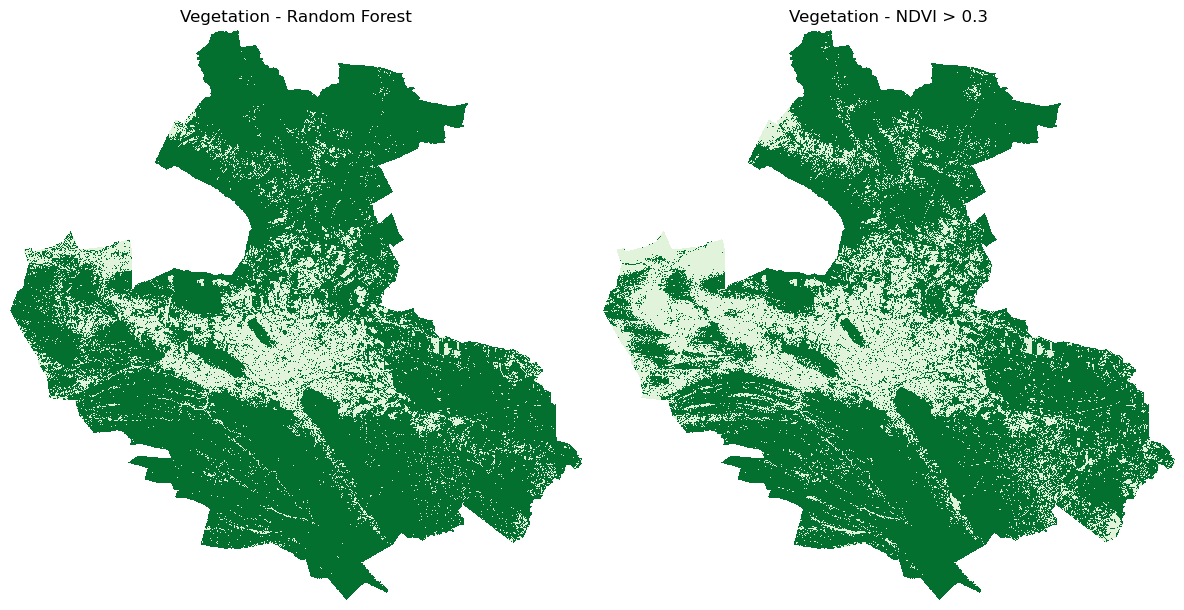

In [6]:
step=10   # draw 1 of every 10 pixels, the full map is too big to plot

def showMask(ax,m,title):
    m=m[::step,::step].astype('float32')
    m[m==noData]=np.nan
    ax.imshow(m,cmap='Greens',vmin=-0.2,vmax=1.2,interpolation='nearest')
    ax.set_title(title)
    ax.axis('off')

fig,axes=plt.subplots(1,2,figsize=(12,6))
showMask(axes[0],greenRf,'Vegetation - Random Forest')
showMask(axes[1],greenNdvi,'Vegetation - NDVI > 0.3')
plt.tight_layout()
plt.savefig(resultsFolder/'green_map_zmm.png',dpi=200,bbox_inches='tight')
plt.show()